In [1]:
import numpy as np
import scipy.sparse  as sp
import trimesh
import robust_laplacian

In [2]:
import torch
import torch.nn as nn

Let us look at the simple heat equation equation
$$
\partial_t u(t, x) = k \partial_{xx} u(t, x)
$$


We choose domain for $x \in S^2$

In [3]:
mesh = trimesh.creation.icosphere(subdivisions=3, radius=1.0)

In [4]:
vertices = np.asarray(mesh.vertices)
faces = np.asarray(mesh.faces)

In [5]:
vertices

array([[-0.52573111,  0.85065081,  0.        ],
       [ 0.52573111,  0.85065081,  0.        ],
       [-0.52573111, -0.85065081,  0.        ],
       ...,
       [-0.91298249, -0.39960705,  0.08232358],
       [-0.9663926 , -0.13279248,  0.22011703],
       [-0.96386126, -0.2664047 ,  0.        ]], shape=(642, 3))

In [6]:
mesh

<trimesh.Trimesh(vertices.shape=(642, 3), faces.shape=(1280, 3))>

In [7]:
edges = np.asarray(mesh.edges_unique)

In [8]:
edges

array([[  0, 162],
       [ 42, 162],
       [ 12, 163],
       ...,
       [628, 641],
       [637, 641],
       [639, 641]], shape=(1920, 2))

In [9]:
src = np.concatenate([edges[:, 0], edges[:, 1]])
dst = np.concatenate([edges[:, 1], edges[:, 0]])

In [10]:
A = sp.coo_matrix(
    (np.ones(len(src)), (src, dst)),
    shape=(len(vertices), len(vertices))
).tocsr()

In [11]:
D = sp.diags(np.asarray(A.sum(axis=1)).ravel())

In [12]:
L_graph = D-A 

The Laplace Beltrami operator is written as 
$$ L = M^{-1} S$$
where $M$ is the Mass matrix and $S$ is the stiffness matrix. 

In [13]:
S, M = robust_laplacian.mesh_laplacian(
    vertices,
    faces
)

In [14]:
M_inv = sp.diags(1.0 / M.diagonal())
L_lbo = M_inv @ S

In [31]:
from scipy.sparse.linalg import eigsh, expm_multiply

mass_np = M.diagonal().astype(np.float64)

if np.any(mass_np <= 0):
    raise ValueError("All vertex masses must be positive.")

# Symmetric version M^{-1/2} S M^{-1/2}
M_inv_sqrt = sp.diags(1.0 / np.sqrt(mass_np))

L_symmetric = (
    M_inv_sqrt @ S @ M_inv_sqrt
).tocsr()

n_vertices = len(vertices)
n_modes = min(64, n_vertices - 2)

eigenvalues, symmetric_eigenvectors = eigsh(
    L_symmetric,
    k=n_modes,
    sigma=1e-8,
    which="LM",
)

order = np.argsort(eigenvalues)

eigenvalues = np.maximum(
    eigenvalues[order],
    0.0,
)

symmetric_eigenvectors = (
    symmetric_eigenvectors[:, order]
)

# Convert back to generalized eigenvectors:
# S Phi = M Phi Lambda
Phi = M_inv_sqrt @ symmetric_eigenvectors
Phi = np.asarray(Phi)

print("Eigenvalues:", eigenvalues[:12])

orthogonality_error = np.linalg.norm(
    Phi.T @ (mass_np[:, None] * Phi)
    - np.eye(n_modes)
)

print("M-orthogonality error:", orthogonality_error)

Eigenvalues: [ 0.          1.99999189  1.99999189  1.99999189  5.96585791  5.96585791
  5.96585791  5.96585791  5.96585791 11.82699025 11.82699025 11.82699025]
M-orthogonality error: 1.3751767078415384e-14


Heat Equation

In [32]:
rng = np.random.default_rng(42)

diffusivity = 0.1
final_time = 1.0

# Effective heat time in exp(-tau L)
tau = diffusivity * final_time

# Smooth the random initial conditions
initial_smoothing_time = 0.03

n_train = 64
n_validation = 16
n_test = 16
n_total = n_train + n_validation + n_test

raw_fields = rng.normal(
    size=(n_total, n_vertices)
)

L_lbo = L_lbo.astype(np.float64).tocsr()

# Make the random initial conditions spatially smooth
u0 = expm_multiply(
    -initial_smoothing_time * L_lbo,
    raw_fields.T,
).T

# Remove the constant spherical mode
weighted_mean = (
    (u0 * mass_np[None, :]).sum(axis=1)
    / mass_np.sum()
)

u0 = u0 - weighted_mean[:, None]

# Normalize every initial condition
weighted_rms = np.sqrt(
    (u0**2 * mass_np[None, :]).sum(axis=1)
    / mass_np.sum()
)

u0 = u0 / weighted_rms[:, None]

# Ground-truth heat solution
uT = expm_multiply(
    -tau * L_lbo,
    u0.T,
).T

print("Input shape:", u0.shape)
print("Target shape:", uT.shape)
print("Effective heat time:", tau)

Input shape: (96, 642)
Target shape: (96, 642)
Effective heat time: 0.1


Dataset

In [33]:
from torch.utils.data import TensorDataset, DataLoader

u0_tensor = torch.tensor(
    u0,
    dtype=torch.float32,
).unsqueeze(-1)  # [N,V,1]

uT_tensor = torch.tensor(
    uT,
    dtype=torch.float32,
).unsqueeze(-1)  # [N,V,1]

train_dataset = TensorDataset(
    u0_tensor[:n_train],
    uT_tensor[:n_train],
)

validation_dataset = TensorDataset(
    u0_tensor[n_train:n_train + n_validation],
    uT_tensor[n_train:n_train + n_validation],
)

test_dataset = TensorDataset(
    u0_tensor[-n_test:],
    uT_tensor[-n_test:],
)

batch_size = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=batch_size,
    shuffle=False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

mass_tensor = torch.tensor(
    mass_np,
    dtype=torch.float32,
    device=device,
)

eigenvalues_tensor = torch.tensor(
    eigenvalues,
    dtype=torch.float32,
)

Phi_tensor = torch.tensor(
    Phi,
    dtype=torch.float32,
)

print("Device:", device)

Device: cpu


Loss and Metric

In [34]:
def mass_weighted_mse(
    prediction: torch.Tensor,
    target: torch.Tensor,
) -> torch.Tensor:

    weights = mass_tensor[None, :, None]

    squared_error = (
        weights * (prediction - target).square()
    ).sum()

    normalization = (
        prediction.shape[0]
        * prediction.shape[2]
        * mass_tensor.sum()
    )

    return squared_error / normalization


@torch.no_grad()
def evaluate(
    model: nn.Module,
    loader: DataLoader,
) -> tuple[float, float]:

    model.eval()

    mse_values = []
    relative_errors = []

    weights = mass_tensor[None, :, None]

    for inputs, targets in loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        predictions = model(inputs)

        mse_values.append(
            mass_weighted_mse(
                predictions,
                targets,
            ).item()
        )

        numerator = (
            weights
            * (predictions - targets).square()
        ).sum(dim=(1, 2))

        denominator = (
            weights * targets.square()
        ).sum(dim=(1, 2)).clamp_min(1e-12)

        relative_errors.append(
            torch.sqrt(numerator / denominator).cpu()
        )

    mean_mse = float(np.mean(mse_values))

    mean_relative_error = torch.cat(
        relative_errors
    ).mean().item()

    return mean_mse, mean_relative_error

Model

In [35]:
import model
from model import HeatKernel, IntegralOperator, IntegralOperatorModel

In [43]:
diffusion_times = np.array(
    [
        0.0,
        tau / 4.0,
        tau / 2.0,
        tau,
        2.0 * tau,
        1
    ],
    dtype=np.float32,
)


def build_model(
    n_blocks: int,
    hidden_channels: int = 8,
    freeze_phi: bool = True,
) -> IntegralOperatorModel:

    layers = []

    for _ in range(n_blocks):
        kernel = HeatKernel(
            eigenvalues=eigenvalues_tensor,
            eigenvectors=Phi_tensor,
            mass=mass_np,
            in_channels=1,
            out_channels=1,
            diffusion_times=diffusion_times,
        )

        block = IntegralOperator(
            kernel=kernel,
            hidden_channels=hidden_channels,
        )

        # Stable initialization:
        # phi(f(v),f(u)) = 1
        # kernel initially selects t=0, i.e. identity
        with torch.no_grad():
            block.phi[-1].weight.zero_()
            block.phi[-1].bias.fill_(1.0)

            block.kernel.coefficients.zero_()
            block.kernel.coefficients[0, 0, 0] = 1.0

        if freeze_phi:
            for parameter in block.phi.parameters():
                parameter.requires_grad_(False)

        layers.append(block)

    model = IntegralOperatorModel(layers)

    # Do not use LeakyReLU for the signed linear heat equation
    model.activation = nn.Identity()

    return model.to(device)

In [44]:
torch.manual_seed(42)

one_block_model = build_model(
    n_blocks=1,
    hidden_channels=8,
    freeze_phi=True,
)

torch.manual_seed(42)

four_block_model = build_model(
    n_blocks=4,
    hidden_channels=8,
    freeze_phi=True,
)

print(
    "One-block trainable parameters:",
    sum(
        p.numel()
        for p in one_block_model.parameters()
        if p.requires_grad
    ),
)

print(
    "Four-block trainable parameters:",
    sum(
        p.numel()
        for p in four_block_model.parameters()
        if p.requires_grad
    ),
)

One-block trainable parameters: 6
Four-block trainable parameters: 24


Training

In [45]:
import copy


def train_model(
    model: nn.Module,
    n_epochs: int = 60,
    learning_rate: float = 5e-3,
) -> dict[str, list[float]]:

    trainable_parameters = [
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ]

    optimizer = torch.optim.Adam(
        trainable_parameters,
        lr=learning_rate,
    )

    history = {
        "train_loss": [],
        "validation_error": [],
    }

    best_validation_error = float("inf")
    best_state = None

    for epoch in range(1, n_epochs + 1):
        model.train()

        epoch_losses = []

        for inputs, targets in train_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()

            predictions = model(inputs)

            loss = mass_weighted_mse(
                predictions,
                targets,
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                trainable_parameters,
                max_norm=1.0,
            )

            optimizer.step()

            epoch_losses.append(loss.item())

        train_loss = float(np.mean(epoch_losses))

        _, validation_error = evaluate(
            model,
            validation_loader,
        )

        history["train_loss"].append(train_loss)
        history["validation_error"].append(
            validation_error
        )

        if validation_error < best_validation_error:
            best_validation_error = validation_error
            best_state = copy.deepcopy(
                model.state_dict()
            )

        if epoch == 1 or epoch % 10 == 0:
            print(
                f"Epoch {epoch:3d} | "
                f"train MSE {train_loss:.4e} | "
                f"validation relative L2 "
                f"{validation_error:.4e}"
            )

    model.load_state_dict(best_state)

    return history

In [46]:
history_one = train_model(
    one_block_model,
    n_epochs=100,
    learning_rate=2e-3,
)

Epoch   1 | train MSE 3.9544e-01 | validation relative L2 1.2927e+00
Epoch  10 | train MSE 6.1243e-02 | validation relative L2 5.4250e-01
Epoch  20 | train MSE 1.3932e-02 | validation relative L2 2.6187e-01
Epoch  30 | train MSE 7.1105e-03 | validation relative L2 1.9087e-01
Epoch  40 | train MSE 4.0192e-03 | validation relative L2 1.4358e-01
Epoch  50 | train MSE 2.0614e-03 | validation relative L2 1.0232e-01
Epoch  60 | train MSE 9.5688e-04 | validation relative L2 6.9421e-02
Epoch  70 | train MSE 4.2454e-04 | validation relative L2 4.5922e-02
Epoch  80 | train MSE 2.0207e-04 | validation relative L2 3.1663e-02
Epoch  90 | train MSE 1.1760e-04 | validation relative L2 2.4299e-02
Epoch 100 | train MSE 8.2359e-05 | validation relative L2 2.0541e-02


In [40]:
history_four = train_model(
    four_block_model,
    n_epochs=80,
    learning_rate=2e-3,
)

Epoch   1 | train MSE 2.6951e-01 | validation relative L2 9.2864e-01


KeyboardInterrupt: 

In [41]:
one_test_mse, one_test_relative = evaluate(
    one_block_model,
    test_loader,
)


print(
    f"One block  | MSE: {one_test_mse:.4e} | "
    f"relative L2: {100 * one_test_relative:.3f}%"
)

One block  | MSE: 7.3262e-07 | relative L2: 0.209%


In [ ]:
one_test_mse, one_test_relative = evaluate(
    one_block_model,
    test_loader,
)

four_test_mse, four_test_relative = evaluate(
    four_block_model,
    test_loader,
)

print(
    f"One block  | MSE: {one_test_mse:.4e} | "
    f"relative L2: {100 * one_test_relative:.3f}%"
)

print(
    f"Four blocks | MSE: {four_test_mse:.4e} | "
    f"relative L2: {100 * four_test_relative:.3f}%"
)

One block  | MSE: 7.2689e-06 | relative L2: 0.635%
Four blocks | MSE: 4.5604e-04 | relative L2: 5.227%


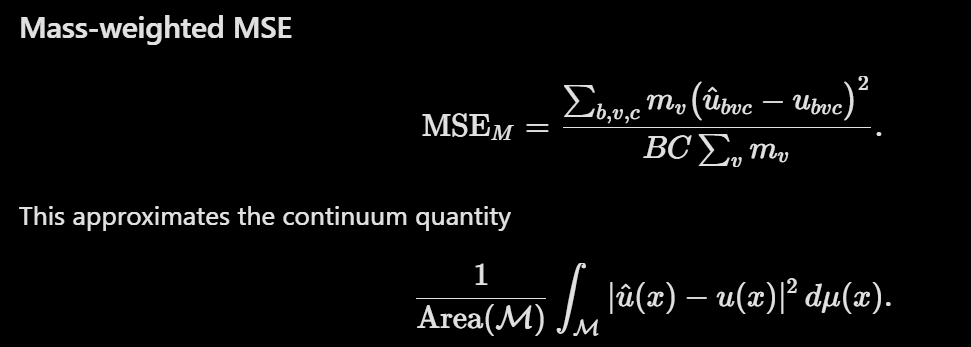

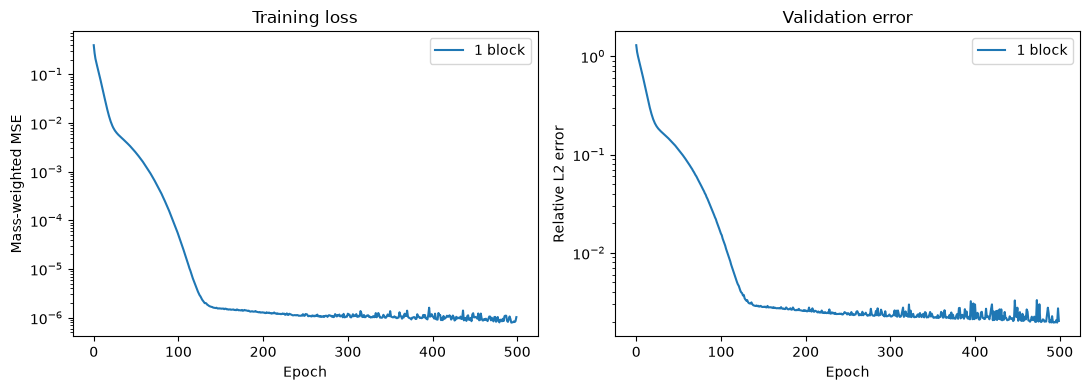

In [42]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4),
)

axes[0].semilogy(
    history_one["train_loss"],
    label="1 block",
)

# axes[0].semilogy(
#     history_four["train_loss"],
#     label="4 blocks",
# )

axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mass-weighted MSE")
axes[0].legend()

axes[1].semilogy(
    history_one["validation_error"],
    label="1 block",
)

# axes[1].semilogy(
#     history_four["validation_error"],
#     label="4 blocks",
# )

axes[1].set_title("Validation error")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Relative L2 error")
axes[1].legend()

plt.tight_layout()
plt.show()

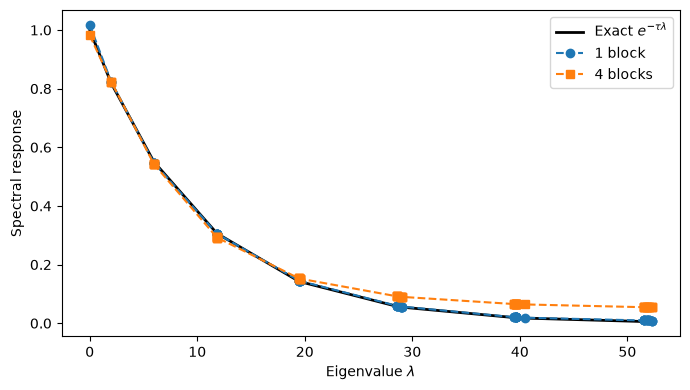

In [ ]:
@torch.no_grad()
def effective_spectral_response(
    model: IntegralOperatorModel,
) -> np.ndarray:

    response = torch.ones_like(
        model.layers[0].kernel.eigenvalues
    )

    for layer in model.layers:
        E = layer.kernel.exp_basis()  # [R,m]

        coefficients = (
            layer.kernel.coefficients[:, 0, 0]
        )  # [R]

        layer_response = torch.einsum(
            "rm,r->m",
            E,
            coefficients,
        )

        response = response * layer_response

    return response.cpu().numpy()


exact_response = np.exp(
    -tau * eigenvalues
)

one_response = effective_spectral_response(
    one_block_model
)

four_response = effective_spectral_response(
    four_block_model
)

plt.figure(figsize=(7, 4))

plt.plot(
    eigenvalues,
    exact_response,
    "k-",
    linewidth=2,
    label=r"Exact $e^{-\tau\lambda}$",
)

plt.plot(
    eigenvalues,
    one_response,
    "o--",
    label="1 block",
)

plt.plot(
    eigenvalues,
    four_response,
    "s--",
    label="4 blocks",
)

plt.xlabel(r"Eigenvalue $\lambda$")
plt.ylabel("Spectral response")
plt.legend()
plt.tight_layout()
plt.show()

Some non linear stuff - vibe coded

$\partial_t​ u=\Kappa \Delta_{S^2} ​u+\rho(u−u^3)$

In [ ]:
from scipy.sparse.linalg import splu, expm_multiply

rng = np.random.default_rng(42)

diffusivity = 0.05
reaction_rate = 5.0
final_time = 0.25

n_time_steps = 100
dt = final_time / n_time_steps

n_train = 64
n_validation = 16
n_test = 16
n_total = n_train + n_validation + n_test

# Generate random fields
raw_fields = rng.normal(
    size=(n_total, n_vertices)
)

# Smooth them spatially
u0 = expm_multiply(
    -0.03 * L_lbo,
    raw_fields.T,
).T

# Remove constant mode
weighted_mean = (
    (u0 * mass_np[None, :]).sum(axis=1)
    / mass_np.sum()
)

u0 = u0 - weighted_mean[:, None]

# Scale fields into approximately [-0.9, 0.9]
maximum = np.max(
    np.abs(u0),
    axis=1,
    keepdims=True,
)

amplitude = rng.uniform(
    0.6,
    0.9,
    size=(n_total, 1),
)

u0 = amplitude * u0 / np.maximum(maximum, 1e-12)

In [ ]:
def solve_allen_cahn(
    initial_conditions: np.ndarray,
    diffusivity: float,
    reaction_rate: float,
    final_time: float,
    n_steps: int,
) -> np.ndarray:

    dt = final_time / n_steps

    implicit_matrix = (
        sp.eye(n_vertices)
        + dt * diffusivity * L_lbo
    ).tocsc()

    # Factorize once, then reuse at every timestep
    linear_solver = splu(implicit_matrix)

    u = initial_conditions.astype(
        np.float64
    ).copy()

    for _ in range(n_steps):
        reaction = reaction_rate * (
            u - u**3
        )

        right_hand_side = (
            u + dt * reaction
        )

        # splu expects [V,N]
        u = linear_solver.solve(
            right_hand_side.T
        ).T

    return u


uT = solve_allen_cahn(
    initial_conditions=u0,
    diffusivity=diffusivity,
    reaction_rate=reaction_rate,
    final_time=final_time,
    n_steps=n_time_steps,
)

print("Input range:", u0.min(), u0.max())
print("Output range:", uT.min(), uT.max())

Input range: -0.893610988243511 0.8981176948053727
Output range: -0.9646906821786462 0.9622800803163782


In [ ]:
u0_tensor = torch.tensor(
    u0,
    dtype=torch.float32,
).unsqueeze(-1)

uT_tensor = torch.tensor(
    uT,
    dtype=torch.float32,
).unsqueeze(-1)

train_dataset = TensorDataset(
    u0_tensor[:n_train],
    uT_tensor[:n_train],
)

validation_dataset = TensorDataset(
    u0_tensor[n_train:n_train + n_validation],
    uT_tensor[n_train:n_train + n_validation],
)

test_dataset = TensorDataset(
    u0_tensor[-n_test:],
    uT_tensor[-n_test:],
)

batch_size = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=batch_size,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
)

In [ ]:
effective_heat_time = (
    diffusivity * final_time
)

diffusion_times = np.array(
    [
        0.0,
        effective_heat_time / 8,
        effective_heat_time / 4,
        effective_heat_time / 2,
        effective_heat_time,
        2 * effective_heat_time,
    ],
    dtype=np.float32,
)


def build_allen_cahn_model(
    n_blocks: int,
    hidden_channels: int = 32,
) -> IntegralOperatorModel:

    layers = []

    for _ in range(n_blocks):
        kernel = HeatKernel(
            eigenvalues=eigenvalues_tensor,
            eigenvectors=Phi_tensor,
            mass=mass_np,
            in_channels=1,
            out_channels=1,
            diffusion_times=diffusion_times,
        )

        block = IntegralOperator(
            kernel=kernel,
            hidden_channels=hidden_channels,
        )

        with torch.no_grad():
            # Begin close to phi = 1, but keep it trainable
            nn.init.normal_(
                block.phi[-1].weight,
                mean=0.0,
                std=1e-3,
            )
            block.phi[-1].bias.fill_(1.0)

            # Begin close to the identity operator
            block.kernel.coefficients.zero_()
            block.kernel.coefficients[0, 0, 0] = 1.0

        # Nothing is frozen
        layers.append(block)

    model = IntegralOperatorModel(layers)

    # Phi already provides the nonlinearity.
    # Identity also preserves the u -> -u symmetry.
    model.activation = nn.Identity()

    return model.to(device)

In [ ]:
torch.manual_seed(42)

one_block_nonlinear = build_allen_cahn_model(
    n_blocks=1,
    hidden_channels=32,
)

torch.manual_seed(42)

four_block_nonlinear = build_allen_cahn_model(
    n_blocks=4,
    hidden_channels=32,
)


def count_trainable_parameters(model):
    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )


print(
    "One block:",
    count_trainable_parameters(
        one_block_nonlinear
    ),
)

print(
    "Four blocks:",
    count_trainable_parameters(
        four_block_nonlinear
    ),
)

One block: 135
Four blocks: 540


In [ ]:
history_one_nonlinear = train_model(
    one_block_nonlinear,
    n_epochs=100,
    learning_rate=2e-3,
)

Epoch   1 | train MSE 4.9789e-03 | validation relative L2 1.3363e-01
Epoch  10 | train MSE 3.4006e-03 | validation relative L2 1.1003e-01
Epoch  20 | train MSE 3.1104e-03 | validation relative L2 1.0525e-01
Epoch  30 | train MSE 3.0076e-03 | validation relative L2 1.0453e-01


In [ ]:
history_one_nonlinear = train_model(
    one_block_nonlinear,
    n_epochs=100,
    learning_rate=2e-3,
)

In [ ]:
one_mse, one_relative = evaluate(
    one_block_nonlinear,
    test_loader,
)

four_mse, four_relative = evaluate(
    four_block_nonlinear,
    test_loader,
)

print(
    f"One block  | MSE: {one_mse:.4e} | "
    f"relative L2: {100 * one_relative:.3f}%"
)

print(
    f"Four blocks | MSE: {four_mse:.4e} | "
    f"relative L2: {100 * four_relative:.3f}%"
)